# Introduction to Unsupervised Learning


**Note**: this demonstration was developed using the **3W Dataset 2.0.0** and the **3W Toolkit 3.2.1**; results may differ if other versions were used.

> 📖 **Companion book** — this notebook exercises **Chapter 5** (§*Autoencoders*), **Chapter 6** (§*Quatro escores de novidade*: reconstruction error and one-class SVM) and the dual system of **Chapter 7** of Lopes et al. (2026), *Aprendizado de Mundo Aberto em Poços de Petróleo* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)). **Appendix E** (§*Caderno 3*) discusses the design decisions of this notebook.
>
> 🧰 **3W Toolkit** — what comes from the toolkit here: the windows (`ParquetDataset`, `Normalize` and `Windowing`, built in notebook 1) and the **ROC AUC** (`ThreeWToolkit.metrics.roc_auc_score`). The toolkit has **no anomaly detectors** and its only neural model is the `MLP`; the one-class SVM is scikit-learn's `OneClassSVM` used directly (the `SklearnModelsConfig` validator rejects it because it has no `score` method), and the LSTM autoencoder (**PyTorch**, `src/autoencoder_models.py`), the reconstruction-error thresholds and the ROC *curve* are our own extensions. Because the autoencoder has a sigmoid output, the normal windows are rescaled to [0, 1] after the toolkit normalization. For the toolkit's own training/evaluation components (`MLP`, `ModelTrainer`, `ModelAssessment`) see the [model training tutorial](../introduction_to_3w_toolkit_v2.0.0/7_model_training_and_evaluation.ipynb).

In [1]:
# Environment Setup and Module Imports
import time
import sys

start_time = time.time()

print("Loading 3W Dataset for Autoencoder Novelty Detection")
print("=" * 60)

# Add src to path and import modules
sys.path.append("src")

print("Importing modules...", end=" ")
from src.data_persistence import DataPersistence
from src.unsupervised_preprocessing import UnsupervisedDataLoader
from src import config
import numpy as np

# Initialize components
persistence = DataPersistence(base_dir=config.PROCESSED_DATA_DIR, verbose=False)
data_loader = UnsupervisedDataLoader(persistence, config)

print(f"Using data format: {config.SAVE_FORMAT}")

Loading 3W Dataset for Autoencoder Novelty Detection
Importing modules... 

Using data format: pickle


In [2]:
# Data Loading Configuration for Per-Fold Evaluation
MAX_NORMAL_SAMPLES = (
    config.MAX_NORMAL_SAMPLES
)  # Limit normal samples per fold for faster processing
MAX_ANOMALY_SAMPLES = config.MAX_ANOMALY_SAMPLES  # Limit anomaly samples per fold
SELECTED_ANOMALY_CLASSES = config.SELECTED_ANOMALY_CLASSES  # Target anomaly classes

print("Per-Fold Evaluation Configuration:")
print(f"   • Max normal samples per fold: {MAX_NORMAL_SAMPLES}")
print(f"   • Max anomaly samples per fold: {MAX_ANOMALY_SAMPLES}")
print(f"   • Selected anomaly classes: {SELECTED_ANOMALY_CLASSES}")

Per-Fold Evaluation Configuration:
   • Max normal samples per fold: 500
   • Max anomaly samples per fold: 200
   • Selected anomaly classes: [3, 4, 8]


In [3]:
# Load Data for Per-Fold Evaluation
try:
    fold_data = data_loader.load_per_fold_data(
        selected_anomaly_classes=SELECTED_ANOMALY_CLASSES,
        max_normal_samples=MAX_NORMAL_SAMPLES,
        max_anomaly_samples=MAX_ANOMALY_SAMPLES,
    )

    data_ready = True
    total_time = time.time() - start_time

    print(f"✅ Per-fold data loaded: {len(fold_data)} folds in {total_time:.2f}s")

    # Concise summary per fold
    for fold_name, data in fold_data.items():
        train_size = len(data["train_normal"])
        test_normal_size = len(data["test_normal"])
        test_anomaly_size = len(data["test_anomaly"])
        print(
            f"{fold_name}: {train_size} train, {test_normal_size} test normal, {test_anomaly_size} test anomaly"
        )

except Exception as e:
    print(f"❌ Error: {str(e)}")
    fold_data = {}
    data_ready = False

  train(23191)

  test(5173)

  train(22750)

  test(5614)

  train(23187)

  test(5177)

✅ Per-fold data loaded: 3 folds in 16.64s
fold_1: 500 train, 250 test normal, 200 test anomaly
fold_2: 500 train, 250 test normal, 200 test anomaly
fold_3: 500 train, 250 test normal, 200 test anomaly


# Distance-Based Anomaly Detection

## One-Class SVM (OCSVM) Theory

**One-Class Support Vector Machine** is a powerful unsupervised anomaly detection method that learns the boundary of normal data.

### Mathematical Foundation:

**Objective**: Find a hyperplane that separates normal data from the origin with maximum margin
```
min ||w||² + (1/νn)Σξᵢ - ρ
```

Where:
- `w` = Weight vector defining the hyperplane
- `ν` = Parameter controlling trade-off between training error and margin
- `ξᵢ` = Slack variables for outliers
- `ρ` = Offset from origin

### Key Concepts:

1. **Normal Data Boundary**: OCSVM learns a decision boundary enclosing normal operating patterns
2. **Kernel Trick**: Uses RBF kernel to handle non-linear patterns in high-dimensional space
3. **Anomaly Score**: Distance from the decision boundary (negative = anomaly, positive = normal)
4. **Parameter ν**: Controls the fraction of training data considered as outliers (typically 0.01-0.1)

### Advantages over Autoencoders:
- **Faster Training**: No iterative gradient descent required
- **No Architecture Design**: No need to tune layers, units, or latent dimensions
- **Theoretical Guarantees**: Well-established statistical learning theory
- **Memory Efficient**: Stores only support vectors, not full model weights
- **Deterministic**: Same results on each run (unlike neural networks)

### Detection Process:
1. **Training**: Learn decision boundary using only normal operational data
2. **Scoring**: Compute signed distance to boundary for new samples
3. **Classification**: Samples with negative scores are anomalies

### Implementation Considerations:
- **Feature Scaling**: Critical for distance-based methods
- **Kernel Selection**: RBF kernel works well for time series
- **Parameter Tuning**: ν controls sensitivity vs false positive rate

> 📖 **In the book — Chapter 6, §*Máquina de vetores de suporte de uma classe*, and Appendix E, §*A alternativa geométrica*.** Each window is flattened into a vector of 300 × 3 positions and passed through standardization and the OCSVM. This is the same family of method that, in Chapter 8, obtained **0.65** accuracy against **0.87** for the binary ensemble — and the reason becomes evident when you inspect the dimension of the flattened vector: in 900 dimensions, distances concentrate and the boundary of the normal class loses meaning.

In [4]:
# Distance-Based Anomaly Detection: the one-class SVM
print("Distance-Based Anomaly Detection")
print("=" * 40)

# scikit-learn directly: SklearnModelsConfig rejects OneClassSVM (it has no `score` method).
# The accuracies come from the toolkit metrics.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from ThreeWToolkit.metrics import accuracy_score

# Check if we have data for distance-based detection
if data_ready and fold_data:
    print("✅ Data available for distance-based anomaly detection")
else:
    print("❌ No data available. Please run the data loading cell first.")
    data_ready = False

Distance-Based Anomaly Detection


✅ Data available for distance-based anomaly detection


In [5]:
# Per-Fold Distance-Based Anomaly Detection
if data_ready and fold_data:
    print("Per-Fold One-Class SVM Evaluation")
    print("=" * 35)

    flatten = lambda windows: windows.reshape(windows.shape[0], -1)

    # Store results for each fold
    distance_fold_results = {}

    for fold_name, data in fold_data.items():
        print(f"\n🔄 Processing {fold_name} with One-Class SVM...")

        # Train on normal data only: standardize the flattened windows, then the OCSVM
        ocsvm = Pipeline(
            [
                ("scaler", StandardScaler()),
                ("ocsvm", OneClassSVM(nu=0.05, gamma="scale", kernel="rbf")),
            ]
        )
        ocsvm.fit(flatten(data["train_normal"]))
        print(
            f"   • Training windows: {len(data['train_normal'])} | "
            f"support vectors: {ocsvm.named_steps['ocsvm'].support_vectors_.shape[0]}"
        )

        # Predictions: 1 = normal, -1 = anomaly
        normal_pred = ocsvm.predict(flatten(data["test_normal"]))
        anomaly_pred = ocsvm.predict(flatten(data["test_anomaly"]))
        y_true = np.r_[np.ones(len(normal_pred)), -np.ones(len(anomaly_pred))]

        results = {
            "normal_accuracy": accuracy_score(np.ones(len(normal_pred)), normal_pred),
            "anomaly_accuracy": accuracy_score(-np.ones(len(anomaly_pred)), anomaly_pred),
            "overall_accuracy": accuracy_score(y_true, np.r_[normal_pred, anomaly_pred]),
            # Anomaly score: higher = more anomalous (minus the distance to the boundary)
            "normal_scores": -ocsvm.decision_function(flatten(data["test_normal"])),
            "anomaly_scores": -ocsvm.decision_function(flatten(data["test_anomaly"])),
            "normal_predictions": normal_pred,
            "anomaly_predictions": anomaly_pred,
            "n_normal": len(normal_pred),
            "n_anomaly": len(anomaly_pred),
            "n_support_vectors": ocsvm.named_steps["ocsvm"].support_vectors_.shape[0],
            "anomaly_classes": data["test_anomaly_classes"],
        }
        distance_fold_results[fold_name] = results

        print(
            f"   ✅ Normal: {results['normal_accuracy']:.3f}, Anomaly: {results['anomaly_accuracy']:.3f}"
        )

    distance_evaluation_complete = True

else:
    print("Cannot proceed - no fold data available")
    distance_evaluation_complete = False

Per-Fold One-Class SVM Evaluation

🔄 Processing fold_1 with One-Class SVM...
   • Training windows: 500 | support vectors: 27
   ✅ Normal: 0.940, Anomaly: 0.900

🔄 Processing fold_2 with One-Class SVM...
   • Training windows: 500 | support vectors: 26
   ✅ Normal: 0.908, Anomaly: 0.920

🔄 Processing fold_3 with One-Class SVM...
   • Training windows: 500 | support vectors: 26
   ✅ Normal: 0.916, Anomaly: 0.975


📊 Distance-Based Per-Fold Performance Summary

Fold       Normal   Anomaly  Overall 
----------------------------------------
fold_1     0.940    0.900    0.922   
fold_2     0.908    0.920    0.913   
fold_3     0.916    0.975    0.942   
----------------------------------------
Mean       0.921    0.932    0.926   
Std        0.014    0.032    0.012   


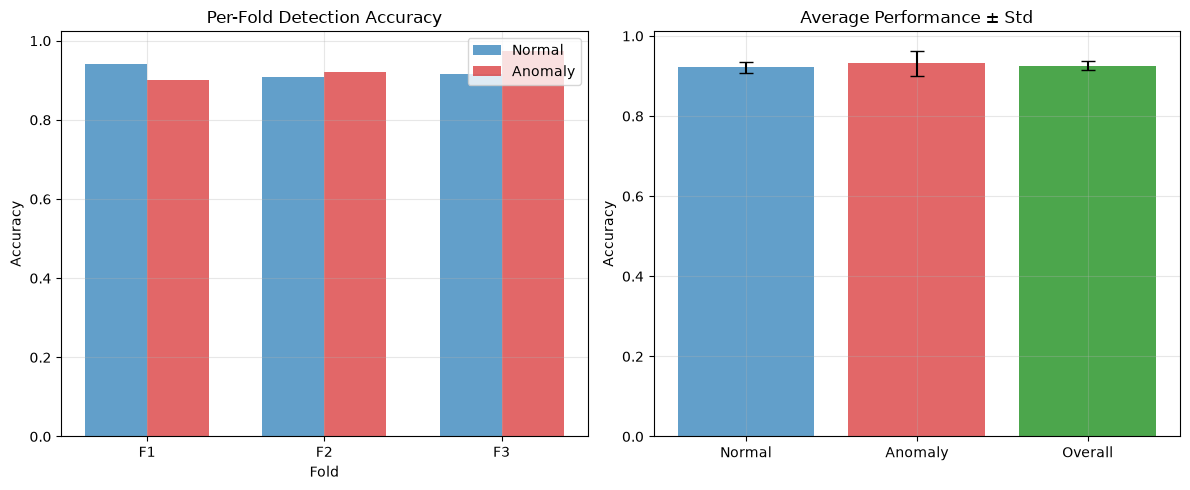


🎯 Distance-Based Summary:
   • Successfully evaluated 3/3 folds
   • Average anomaly detection: 0.932 ± 0.032
   • Average normal accuracy: 0.921 ± 0.014


In [6]:
# Distance-Based Results Summary and Visualization
if distance_evaluation_complete and distance_fold_results:
    print("📊 Distance-Based Per-Fold Performance Summary")
    print("=" * 45)

    # Calculate aggregate statistics
    valid_results = [r for r in distance_fold_results.values() if r is not None]

    if valid_results:
        avg_normal_acc = np.mean([r["normal_accuracy"] for r in valid_results])
        avg_anomaly_acc = np.mean([r["anomaly_accuracy"] for r in valid_results])
        avg_overall_acc = np.mean([r["overall_accuracy"] for r in valid_results])

        std_normal_acc = np.std([r["normal_accuracy"] for r in valid_results])
        std_anomaly_acc = np.std([r["anomaly_accuracy"] for r in valid_results])
        std_overall_acc = np.std([r["overall_accuracy"] for r in valid_results])

        print(f"\n{'Fold':<10} {'Normal':<8} {'Anomaly':<8} {'Overall':<8}")
        print("-" * 40)

        for fold_name, result in distance_fold_results.items():
            if result:
                print(
                    f"{fold_name:<10} {result['normal_accuracy']:<8.3f} {result['anomaly_accuracy']:<8.3f} {result['overall_accuracy']:<8.3f}"
                )

        print("-" * 40)
        print(
            f"{'Mean':<10} {avg_normal_acc:<8.3f} {avg_anomaly_acc:<8.3f} {avg_overall_acc:<8.3f}"
        )
        print(
            f"{'Std':<10} {std_normal_acc:<8.3f} {std_anomaly_acc:<8.3f} {std_overall_acc:<8.3f}"
        )

        # Import visualization class
        from src.visualization import AnomalyDetectionVisualizer

        distance_visualizer = AnomalyDetectionVisualizer()

        # Plot per-fold performance for distance method
        distance_visualizer.plot_per_fold_performance(distance_fold_results)

        print("\n🎯 Distance-Based Summary:")
        print(
            f"   • Successfully evaluated {len(valid_results)}/{len(distance_fold_results)} folds"
        )
        print(
            f"   • Average anomaly detection: {avg_anomaly_acc:.3f} ± {std_anomaly_acc:.3f}"
        )
        print(
            f"   • Average normal accuracy: {avg_normal_acc:.3f} ± {std_normal_acc:.3f}"
        )

    else:
        print("No valid results to display")

else:
    print("Distance-based evaluation not completed")

🏆 Best Performing Fold (Distance-Based): fold_3
   • Overall accuracy: 0.942
   • Normal accuracy: 0.916
   • Anomaly accuracy: 0.975
🏆 Best Performing Fold (Distance-Based): fold_3
   • ROC AUC: 0.986


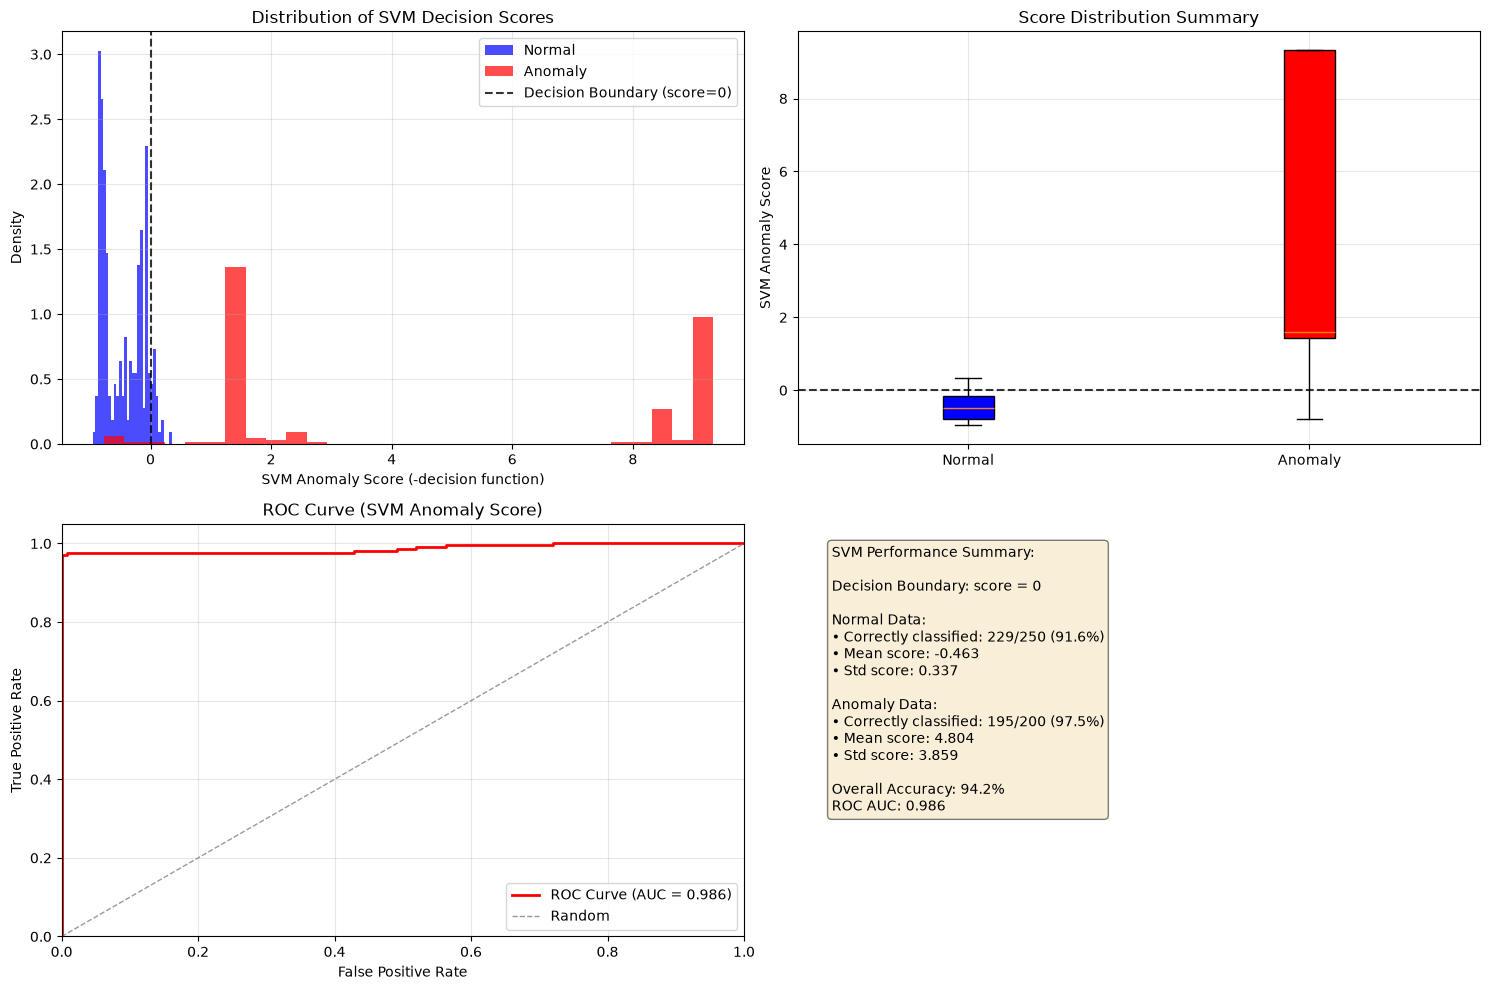


✅ SVM analysis visualization complete!
   • Overall accuracy: 0.942
   • Normal accuracy: 0.916
   • Anomaly accuracy: 0.975
   • ROC AUC: 0.986


In [7]:
# Detailed Distance-Based Analysis
if distance_evaluation_complete and distance_fold_results:
    # Find best performing fold for detailed analysis
    valid_folds = {k: v for k, v in distance_fold_results.items() if v is not None}

    if valid_folds:
        best_fold = max(valid_folds.items(), key=lambda x: x[1]["overall_accuracy"])
        best_fold_name, best_result = best_fold

        print(f"🏆 Best Performing Fold (Distance-Based): {best_fold_name}")
        print(f"   • Overall accuracy: {best_result['overall_accuracy']:.3f}")
        print(f"   • Normal accuracy: {best_result['normal_accuracy']:.3f}")
        print(f"   • Anomaly accuracy: {best_result['anomaly_accuracy']:.3f}")

        # Get the best fold's results for detailed analysis
        normal_scores_best = best_result["normal_scores"]
        anomaly_scores_best = best_result["anomaly_scores"]
        anomaly_classes_best = best_result["anomaly_classes"]

        # Use the enhanced visualization method from the module
        from src.visualization import AnomalyDetectionVisualizer

        distance_visualizer = AnomalyDetectionVisualizer()

        # Create comprehensive SVM analysis visualization
        svm_results = distance_visualizer.plot_svm_analysis(
            normal_scores_best,
            anomaly_scores_best,
            anomaly_classes_best,
            fold_name=best_fold_name,
        )

        print("\n✅ SVM analysis visualization complete!")
        print(f"   • Overall accuracy: {svm_results['overall_accuracy']:.3f}")
        print(f"   • Normal accuracy: {svm_results['normal_accuracy']:.3f}")
        print(f"   • Anomaly accuracy: {svm_results['anomaly_accuracy']:.3f}")
        print(f"   • ROC AUC: {svm_results['roc_auc']:.3f}")

else:
    print("No results available for detailed distance-based analysis")

## Autoencoder Architecture

An autoencoder is a neural network designed to learn efficient data representations through reconstruction. It consists of:

### Components:
1. **Encoder**: Compresses input data into a lower-dimensional latent representation
2. **Decoder**: Reconstructs the original input from the latent representation
3. **Latent Space**: The compressed representation capturing essential patterns

```
Input → [Encoder] → Latent Space → [Decoder] → Reconstructed Output
```

## Reconstruction Error Principle

The reconstruction error measures the difference between original input and autoencoder output. This error serves as an anomaly indicator.

### Mathematical Foundation:

**Reconstruction Error Formula:**
```
Error = ||x - x̂||²
```
Where:
- `x` = Original input
- `x̂` = Reconstructed output
- `||·||²` = Squared Euclidean norm (L2 norm)

### Anomaly Detection Mechanism:

1. **Normal Pattern Learning**: During training on normal data, the autoencoder learns to efficiently encode and decode typical patterns
2. **Compression Efficiency**: Normal patterns are represented in the latent space with low reconstruction error
3. **Anomaly Detection**: Anomalous patterns cannot be efficiently compressed using learned normal representations
4. **Error Threshold**: Higher reconstruction errors indicate deviations from learned normal patterns

## Detection Process

### 1. Training Phase (Normal Data Only):
```python
# Train autoencoder on normal patterns
for normal_sample in normal_data:
    latent = encoder(normal_sample)
    reconstructed = decoder(latent)
    loss = mse(normal_sample, reconstructed)
    # Minimize reconstruction error for normal patterns
```

### 2. Threshold Determination:
Calculate reconstruction errors on normal validation data and set threshold using:
- **Statistical method**: `threshold = μ + k×σ` (typically k=2 or 3)
- **Percentile-based**: 95th or 99th percentile of normal errors
- **ROC optimization**: Threshold that maximizes true positive rate

### 3. Detection Phase:
```python
# Detect anomalies in new data
reconstruction_error = ||x_new - autoencoder(x_new)||²
is_anomaly = reconstruction_error > threshold
```

## Statistical Foundation

### Normal Data Distribution:
- Reconstruction errors follow normal distribution for typical data
- Low mean error with small variance
- Predictable error patterns

### Anomaly Characteristics:
- Higher reconstruction errors due to poor fit with learned patterns
- Outlier behavior in error distribution
- Pattern deviation from training distribution

### Performance Metrics:
1. **True Positive Rate (Sensitivity)**: Correctly detected anomalies
2. **False Positive Rate**: Normal data incorrectly flagged as anomalous
3. **AUC-ROC**: Area under receiver operating characteristic curve
4. **Precision/Recall**: Trade-off between detection accuracy and false alarms

### Implementation Considerations:

1. **Unsupervised Learning**: Requires only normal operation data
2. **Real-time Detection**: Fast inference for continuous monitoring
3. **Adaptive Thresholds**: Can adjust to changing operational conditions
4. **Multivariate Analysis**: Considers relationships between multiple sensors
5. **Temporal Patterns**: LSTM autoencoders capture time-series dependencies

> 📖 **In the book — Chapters 5 and 7, and Appendix E, §*O limiar*.** `AnomalyDetector.determine_threshold` implements the two policies discussed in the book: the **percentile** of the normal errors (95th, as in Chapter 12) and **μ + 2σ** (the book's Chapter 7 uses k = 3). Comparing both on the same errors is a direct way to see that *the choice of the threshold moves the detection / false-alarm trade-off far more than the choice of architecture*. Chapter 12 of the book compares the reconstruction error with the Mahalanobis distance computed in the latent space.

## 📊 Per-Fold Evaluation Strategy

### Proper Cross-Validation for Unsupervised Learning

**Per-Fold Training**: Train autoencoder on each fold's normal training data only
**Per-Fold Testing**: Evaluate on each fold's normal + anomaly test data

### Benefits of Per-Fold Evaluation:
- More robust performance estimates
- Prevents data leakage between folds
- Shows consistency across different data splits
- Better represents real-world deployment scenarios

In [8]:
# Import Required Libraries for Autoencoder
print("LSTM Autoencoder for Anomaly Detection")
print("=" * 45)

# Import required libraries
import numpy as np
import time

# Import custom modules
from src.autoencoder_models import StableLSTMAutoencoder
from src.anomaly_detection import AnomalyDetector
from src.visualization import AnomalyDetectionVisualizer

# Validate data availability
if data_ready and fold_data:
    print("✅ Data available for processing")
    print(f"   • Folds available: {len(fold_data)}")
    total_samples = sum(
        len(data["train_normal"]) + len(data["test_normal"]) + len(data["test_anomaly"])
        for data in fold_data.values()
    )
    print(f"   • Total samples across all folds: {total_samples}")
else:
    print("❌ No data available. Please run the previous cells first.")
    data_ready = False

LSTM Autoencoder for Anomaly Detection


✅ Data available for processing
   • Folds available: 3
   • Total samples across all folds: 2850


## 🧠 LSTM Autoencoder Architecture

### Why LSTM Autoencoders for Time Series?

**LSTM (Long Short-Term Memory)** networks are perfect for time series data because they:
- Remember long-term dependencies in sensor readings
- Capture temporal patterns in oil well operations
- Handle variable-length sequences effectively

### Autoencoder Components:
1. **LSTM Encoder**: Compresses time series into fixed-size latent vector
2. **Latent Space**: Compact representation of input patterns
3. **LSTM Decoder**: Reconstructs original time series from latent vector

### The Learning Process:
```
Normal Data → [LSTM Encoder] → Latent Vector → [LSTM Decoder] → Reconstructed Data
                                      ↓
                               Minimize reconstruction error
```

During training, the model learns to efficiently represent normal operation patterns.

This implementation uses a modular approach with reusable components in the `src/` directory:

### Modules:

1. **`autoencoder_models.py`** - Contains the `StableLSTMAutoencoder` class with:
   - Stable architecture with gradient clipping
   - Conservative hyperparameters for numerical stability
   - Built-in training and prediction methods

2. **`unsupervised_preprocessing.py`** - Contains the `UnsupervisedDataLoader` class and `prepare_arrays` with:
   - Per-fold loading, with seeded sampling of the windows
   - Data validation and conversion to arrays
   - Rescaling to [0, 1] for the sigmoid output

3. **`anomaly_detection.py`** - Contains the `AnomalyDetector` class with:
   - Reconstruction error computation
   - Threshold determination methods
   - Performance evaluation and visualization

## 🏗️ Building and Training the Autoencoder

### Model Architecture Parameters

**Latent Dimension**: The "bottleneck" size that forces compression
- Smaller = more compression, may lose important details
- Larger = retains more information, less compression

**LSTM Units**: The "memory capacity" of each LSTM layer
- More units = can learn more complex patterns
- Fewer units = simpler model, faster training

### Training Strategy for Anomaly Detection

**Key Principle**: Train ONLY on normal data
- Model learns to reconstruct typical operational patterns
- Anomalies will have higher reconstruction errors because they weren't seen during training

**No Validation Split**: We use ALL normal data for training
- Maximizes the model's exposure to normal patterns
- Validation would be performed separately on mixed normal/anomaly data

> 📖 **In the book — Appendix E, §*A arquitetura* ("Stability is not an implementation detail").** Every stability choice of `StableLSTMAutoencoder` exists because the alternative fails:
>
> | Decision | Reason |
> |---|---|
> | `tanh` activation in the LSTM/latent layers | more stable than ReLU in recurrent nets; avoids divergence of the internal state |
> | Orthogonal recurrent initialization | preserves the norm of the state along the 300 steps |
> | Gradient clipping (`clipnorm = 1.0`) | contains the exploding gradient typical of long sequences |
> | Learning rate `0.0005` | conservative: trades speed for reliable convergence |
> | Sigmoid output | matches the `[0, 1]` range of the Min-Max rescaling that the loader applies to the windows after the toolkit `Normalize` (range taken from the normal training windows only) |
> | Fixed seeds | reproducibility across runs |
>
> A loss that turns `NaN` in the middle of training is usually blamed on the data; it is the symptom of the choices above. The system of Chapter 7, in operation, adopted ReLU and worked because its bottleneck is much narrower (4 dimensions): these choices interact, and none is universally right. In this resource the model is written in **PyTorch** (same decisions, per-tensor gradient clipping as in Keras' `clipnorm`).

In [9]:
# Per-Fold Training and Evaluation
if data_ready and fold_data:
    print("Per-Fold Autoencoder Training and Evaluation")
    print("=" * 45)

    # Store results for each fold
    fold_results = {}

    for fold_name, data in fold_data.items():
        print(f"\n🔄 Processing {fold_name}...")

        # Get fold data
        train_normal = data["train_normal"]
        test_normal = data["test_normal"]
        test_anomaly = data["test_anomaly"]
        test_anomaly_classes = data["test_anomaly_classes"]
        data_info = data["data_info"]

        # Build and train autoencoder for this fold
        autoencoder = StableLSTMAutoencoder(
            time_steps=data_info["time_steps"],
            n_features=data_info["n_features"],
            latent_dim=32,  # Smaller for efficiency
            lstm_units=64,  # Smaller for efficiency
        )

        model = autoencoder.build_model()

        # Train on fold's normal data only
        training_success = autoencoder.train(
            train_data=train_normal,
            val_data=None,
            epochs=20,  # Fewer epochs for efficiency
            batch_size=32,
            verbose=0,  # Less verbose
        )

        if training_success:
            # Evaluate on this fold's test data
            detector = AnomalyDetector()

            # Compute errors
            normal_errors, anomaly_errors = detector.compute_reconstruction_errors(
                autoencoder=autoencoder,
                normal_data=test_normal,
                anomaly_data=test_anomaly,
            )

            # Determine threshold
            threshold = detector.determine_threshold(method="percentile", percentile=95)

            # Calculate metrics
            metrics = detector.evaluate_detection()

            # Store results
            fold_results[fold_name] = {
                "normal_accuracy": metrics.get("normal_accuracy", 0),
                "anomaly_accuracy": metrics.get("anomaly_accuracy", 0),
                "overall_accuracy": metrics.get("overall_accuracy", 0),
                "threshold": threshold,
                "n_train": len(train_normal),
                "n_test_normal": len(test_normal),
                "n_test_anomaly": len(test_anomaly),
            }

            print(
                f"   ✅ Normal: {metrics.get('normal_accuracy', 0):.3f}, Anomaly: {metrics.get('anomaly_accuracy', 0):.3f}"
            )
        else:
            print("   ❌ Training failed")
            fold_results[fold_name] = None

    evaluation_complete = True

else:
    print("Cannot proceed - no fold data available")
    evaluation_complete = False

Per-Fold Autoencoder Training and Evaluation

🔄 Processing fold_1...
🏗️ Building Stable LSTM Autoencoder:
   • Input shape: (300, 3)
   • Encoder LSTM units: 64
   • Latent dimension: 32
   • Decoder LSTM units: 64
✅ Stable LSTM Autoencoder model created
   • Total parameters: 45,027
   • Gradient clipping enabled (clipnorm=1.0)
   • Conservative learning rate (0.0005)
🚂 Training LSTM Autoencoder:
   • Training samples: 500
   • No validation data - using all data for training
   • Max epochs: 20
   • Batch size: 32


✅ Training successful - no NaN values
   • Final training loss: 0.000886
📊 Computing Reconstruction Errors
🔵 Computing reconstruction errors for normal data...
🔴 Computing reconstruction errors for anomaly data...
✅ Reconstruction errors computed:
   • Normal errors: 250 samples
   • Anomaly errors: 200 samples
   • Normal error range: [0.000352, 0.002184]
   • Anomaly error range: [0.001229, 0.282539]
🎯 Determining Anomaly Threshold (percentile)
📈 Threshold set at 95th percentile: 0.001504
📊 Evaluating Anomaly Detection Performance
🎯 Detection Results:
   • Threshold: 0.001504
   • Normal data accuracy: 0.948 (237/250)
   • Anomaly data accuracy: 0.990 (198/200)
   • Overall accuracy: 0.967
   • False positives (normal as anomaly): 13
   • False negatives (anomaly as normal): 2
   ✅ Normal: 0.948, Anomaly: 0.990

🔄 Processing fold_2...
🏗️ Building Stable LSTM Autoencoder:
   • Input shape: (300, 3)
   • Encoder LSTM units: 64
   • Latent dimension: 32
   • Decoder LSTM units: 64
✅ Sta

✅ Training successful - no NaN values
   • Final training loss: 0.000686
📊 Computing Reconstruction Errors
🔵 Computing reconstruction errors for normal data...
🔴 Computing reconstruction errors for anomaly data...
✅ Reconstruction errors computed:
   • Normal errors: 250 samples
   • Anomaly errors: 200 samples
   • Normal error range: [0.000294, 0.003204]
   • Anomaly error range: [0.000628, 0.290934]
🎯 Determining Anomaly Threshold (percentile)
📈 Threshold set at 95th percentile: 0.001803
📊 Evaluating Anomaly Detection Performance
🎯 Detection Results:
   • Threshold: 0.001803
   • Normal data accuracy: 0.948 (237/250)
   • Anomaly data accuracy: 0.965 (193/200)
   • Overall accuracy: 0.956
   • False positives (normal as anomaly): 13
   • False negatives (anomaly as normal): 7
   ✅ Normal: 0.948, Anomaly: 0.965

🔄 Processing fold_3...
🏗️ Building Stable LSTM Autoencoder:
   • Input shape: (300, 3)
   • Encoder LSTM units: 64
   • Latent dimension: 32
   • Decoder LSTM units: 64
✅ Sta

✅ Training successful - no NaN values
   • Final training loss: 0.000898
📊 Computing Reconstruction Errors
🔵 Computing reconstruction errors for normal data...
🔴 Computing reconstruction errors for anomaly data...
✅ Reconstruction errors computed:
   • Normal errors: 250 samples
   • Anomaly errors: 200 samples
   • Normal error range: [0.000323, 0.003305]
   • Anomaly error range: [0.002450, 0.276307]
🎯 Determining Anomaly Threshold (percentile)
📈 Threshold set at 95th percentile: 0.001802
📊 Evaluating Anomaly Detection Performance
🎯 Detection Results:
   • Threshold: 0.001802
   • Normal data accuracy: 0.948 (237/250)
   • Anomaly data accuracy: 1.000 (200/200)
   • Overall accuracy: 0.971
   • False positives (normal as anomaly): 13
   • False negatives (anomaly as normal): 0
   ✅ Normal: 0.948, Anomaly: 1.000


📊 Per-Fold Performance Summary

Fold       Normal   Anomaly  Overall 
----------------------------------------
fold_1     0.948    0.990    0.967   
fold_2     0.948    0.965    0.956   
fold_3     0.948    1.000    0.971   
----------------------------------------
Mean       0.948    0.985    0.964   
Std        0.000    0.015    0.007   


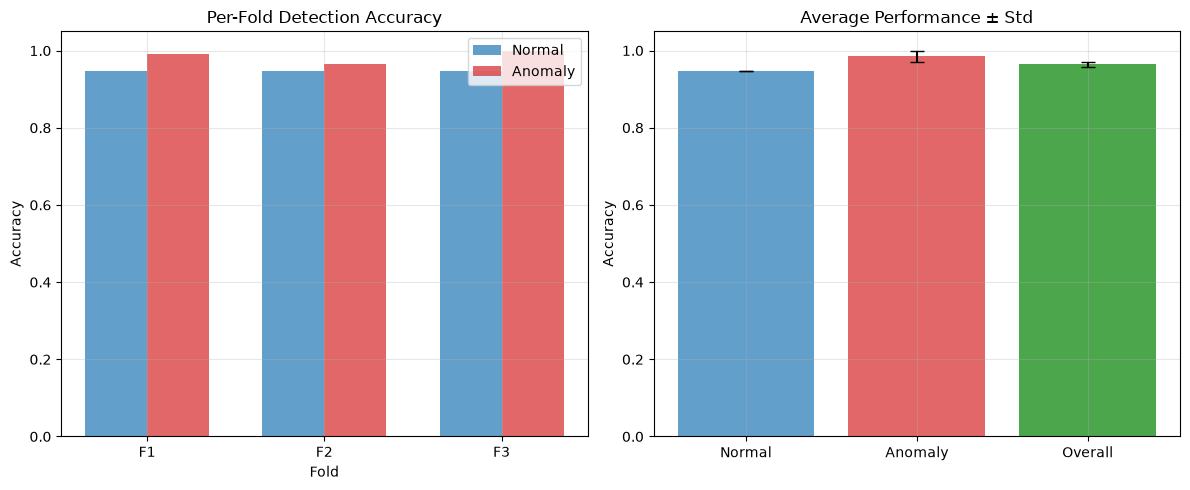


🎯 Summary:
   • Successfully evaluated 3/3 folds
   • Average anomaly detection: 0.985 ± 0.015
   • Average normal accuracy: 0.948 ± 0.000


In [10]:
# Per-Fold Results Summary
if evaluation_complete and fold_results:
    print("📊 Per-Fold Performance Summary")
    print("=" * 35)

    # Calculate aggregate statistics
    valid_results = [r for r in fold_results.values() if r is not None]

    if valid_results:
        avg_normal_acc = np.mean([r["normal_accuracy"] for r in valid_results])
        avg_anomaly_acc = np.mean([r["anomaly_accuracy"] for r in valid_results])
        avg_overall_acc = np.mean([r["overall_accuracy"] for r in valid_results])

        std_normal_acc = np.std([r["normal_accuracy"] for r in valid_results])
        std_anomaly_acc = np.std([r["anomaly_accuracy"] for r in valid_results])
        std_overall_acc = np.std([r["overall_accuracy"] for r in valid_results])

        print(f"\n{'Fold':<10} {'Normal':<8} {'Anomaly':<8} {'Overall':<8}")
        print("-" * 40)

        for fold_name, result in fold_results.items():
            if result:
                print(
                    f"{fold_name:<10} {result['normal_accuracy']:<8.3f} {result['anomaly_accuracy']:<8.3f} {result['overall_accuracy']:<8.3f}"
                )

        print("-" * 40)
        print(
            f"{'Mean':<10} {avg_normal_acc:<8.3f} {avg_anomaly_acc:<8.3f} {avg_overall_acc:<8.3f}"
        )
        print(
            f"{'Std':<10} {std_normal_acc:<8.3f} {std_anomaly_acc:<8.3f} {std_overall_acc:<8.3f}"
        )

        # Use the new visualization class
        from src.visualization import AnomalyDetectionVisualizer

        visualizer = AnomalyDetectionVisualizer()

        # Plot per-fold performance
        visualizer.plot_per_fold_performance(fold_results)

        print("\n🎯 Summary:")
        print(
            f"   • Successfully evaluated {len(valid_results)}/{len(fold_results)} folds"
        )
        print(
            f"   • Average anomaly detection: {avg_anomaly_acc:.3f} ± {std_anomaly_acc:.3f}"
        )
        print(
            f"   • Average normal accuracy: {avg_normal_acc:.3f} ± {std_normal_acc:.3f}"
        )

    else:
        print("No valid results to display")

else:
    print("Per-fold evaluation not completed")

🏆 Best Performing Fold: fold_3
   • Overall accuracy: 0.971
   • Normal accuracy: 0.948
   • Anomaly accuracy: 1.000

Re-training autoencoder on fold_3 for detailed analysis...
🏗️ Building Stable LSTM Autoencoder:
   • Input shape: (300, 3)
   • Encoder LSTM units: 64
   • Latent dimension: 32
   • Decoder LSTM units: 64
✅ Stable LSTM Autoencoder model created
   • Total parameters: 45,027
   • Gradient clipping enabled (clipnorm=1.0)
   • Conservative learning rate (0.0005)
🚂 Training LSTM Autoencoder:
   • Training samples: 500
   • No validation data - using all data for training
   • Max epochs: 20
   • Batch size: 32


✅ Training successful - no NaN values
   • Final training loss: 0.000898
📊 Computing Reconstruction Errors
🔵 Computing reconstruction errors for normal data...
🔴 Computing reconstruction errors for anomaly data...
✅ Reconstruction errors computed:
   • Normal errors: 250 samples
   • Anomaly errors: 200 samples
   • Normal error range: [0.000323, 0.003305]
   • Anomaly error range: [0.002450, 0.276307]

📊 Reconstruction Error Analysis for fold_3


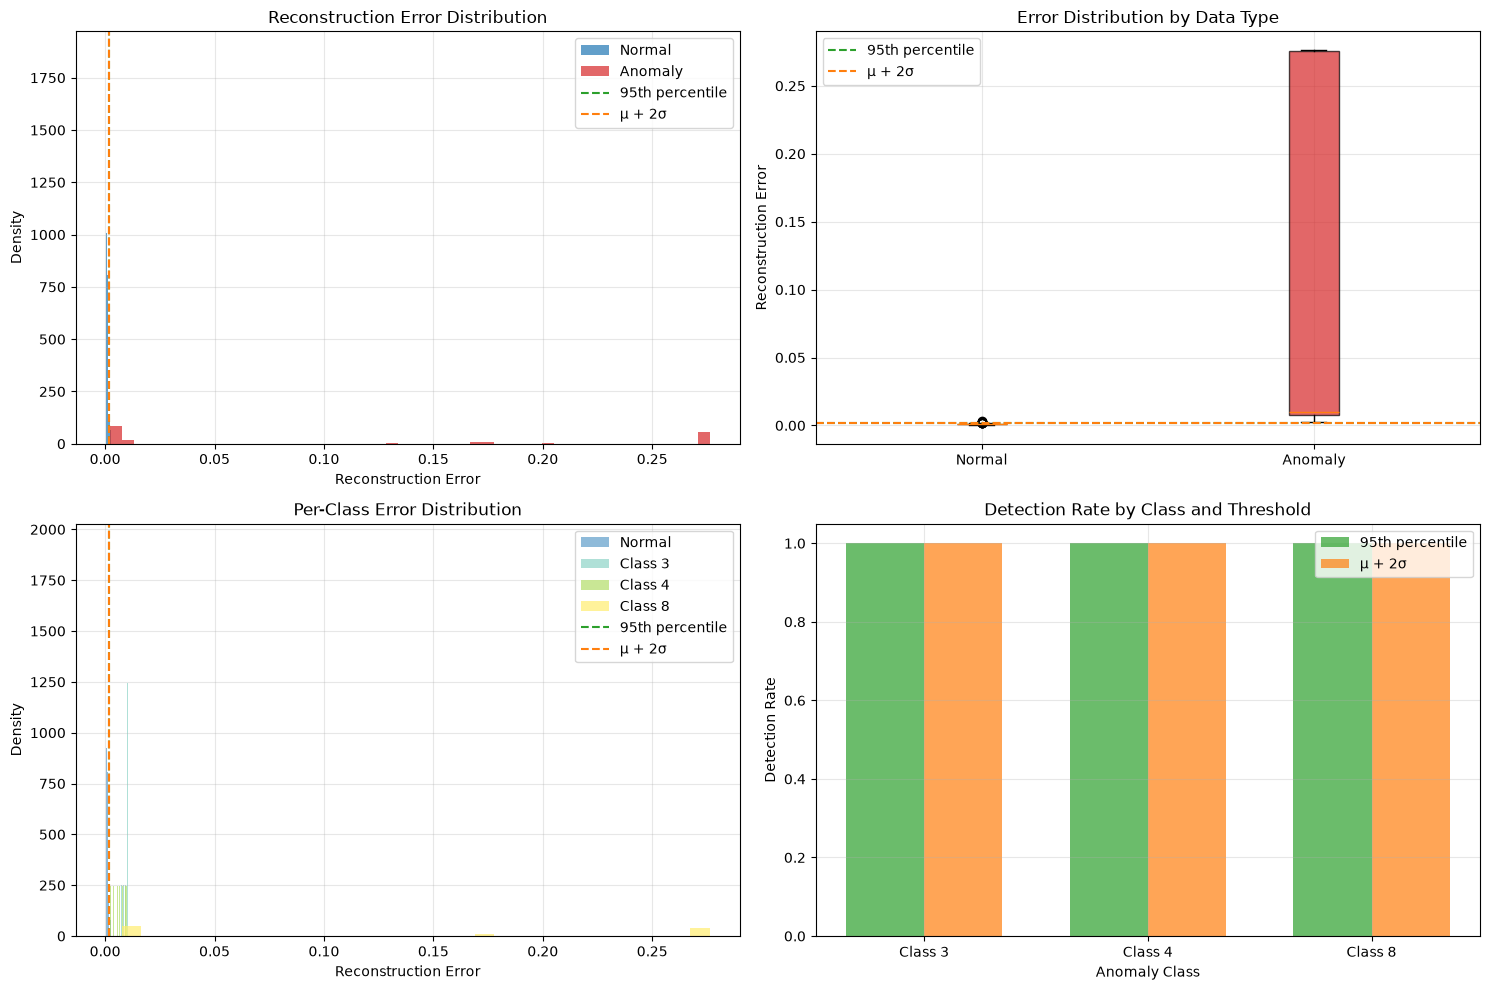

Threshold Analysis:
  • 95th percentile: 0.001802
  • μ + 2σ: 0.001976

🗺️ Latent Space Analysis for fold_3
Computing t-SNE embedding for 450 samples...


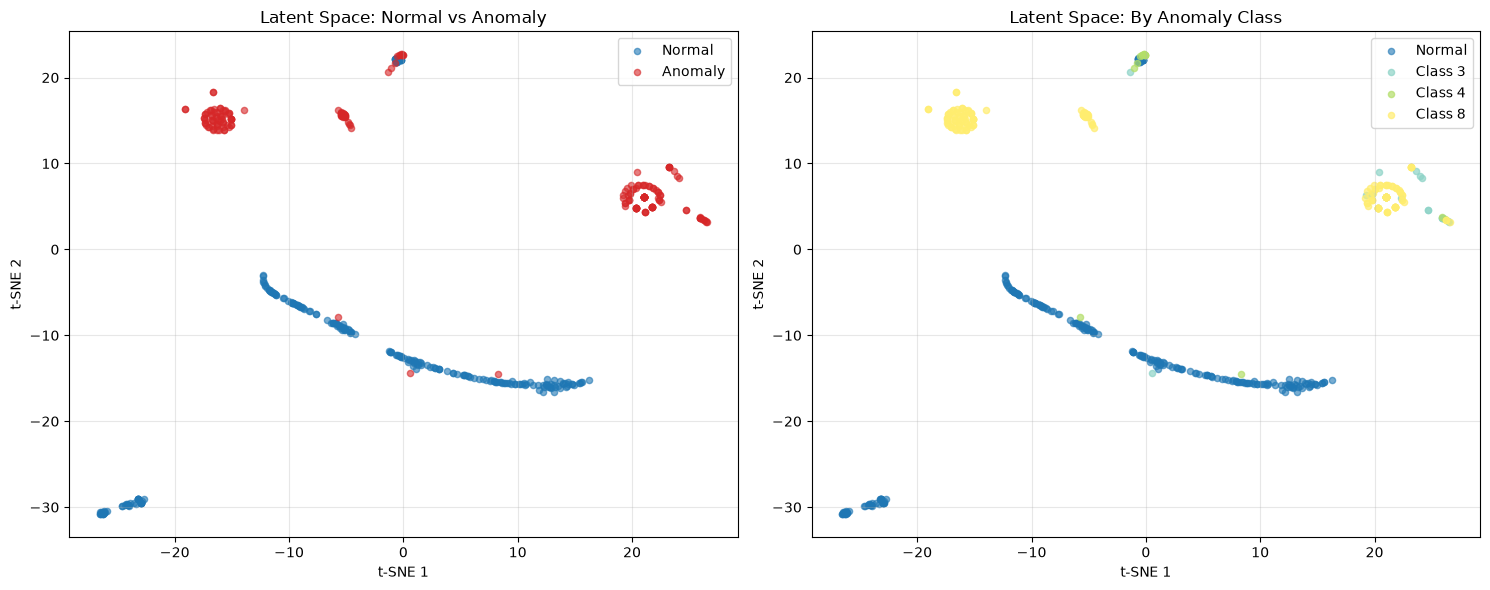

In [11]:
# Detailed Analysis: Reconstruction Errors and Latent Space
if evaluation_complete and fold_results:
    # Find best performing fold for detailed analysis
    valid_folds = {k: v for k, v in fold_results.items() if v is not None}

    if valid_folds:
        best_fold = max(valid_folds.items(), key=lambda x: x[1]["overall_accuracy"])
        best_fold_name, best_result = best_fold

        print(f"🏆 Best Performing Fold: {best_fold_name}")
        print(f"   • Overall accuracy: {best_result['overall_accuracy']:.3f}")
        print(f"   • Normal accuracy: {best_result['normal_accuracy']:.3f}")
        print(f"   • Anomaly accuracy: {best_result['anomaly_accuracy']:.3f}")

        # Get the best fold's data for detailed analysis
        best_fold_data = fold_data[best_fold_name]
        test_normal_best = best_fold_data["test_normal"]
        test_anomaly_best = best_fold_data["test_anomaly"]
        test_anomaly_classes_best = best_fold_data["test_anomaly_classes"]

        # Re-train autoencoder on best fold for visualization
        print(f"\nRe-training autoencoder on {best_fold_name} for detailed analysis...")

        # Build autoencoder
        autoencoder_best = StableLSTMAutoencoder(
            time_steps=best_fold_data["data_info"]["time_steps"],
            n_features=best_fold_data["data_info"]["n_features"],
            latent_dim=32,
            lstm_units=64,
        )
        model_best = autoencoder_best.build_model()

        # Train
        training_success = autoencoder_best.train(
            train_data=best_fold_data["train_normal"],
            val_data=None,
            epochs=20,
            batch_size=32,
            verbose=0,
        )

        if training_success:
            # Compute reconstruction errors
            detector_best = AnomalyDetector()
            normal_errors_best, anomaly_errors_best = (
                detector_best.compute_reconstruction_errors(
                    autoencoder=autoencoder_best,
                    normal_data=test_normal_best,
                    anomaly_data=test_anomaly_best,
                )
            )

            # Visualize reconstruction errors with thresholds
            print(f"\n📊 Reconstruction Error Analysis for {best_fold_name}")
            visualizer.plot_reconstruction_errors(
                normal_errors_best,
                anomaly_errors_best,
                test_anomaly_classes_best,
                threshold_percentile=95,
                threshold_std_multiplier=2,
            )

            # Visualize latent space with t-SNE
            print(f"\n🗺️ Latent Space Analysis for {best_fold_name}")
            visualizer.plot_latent_space_tsne(
                autoencoder_best,
                test_normal_best,
                test_anomaly_best,
                test_anomaly_classes_best,
                max_samples=800,
                perplexity=30,
            )
        else:
            print("Failed to train autoencoder for detailed analysis")

else:
    print("No results available for detailed analysis")


📈 ROC Curve Analysis for fold_3


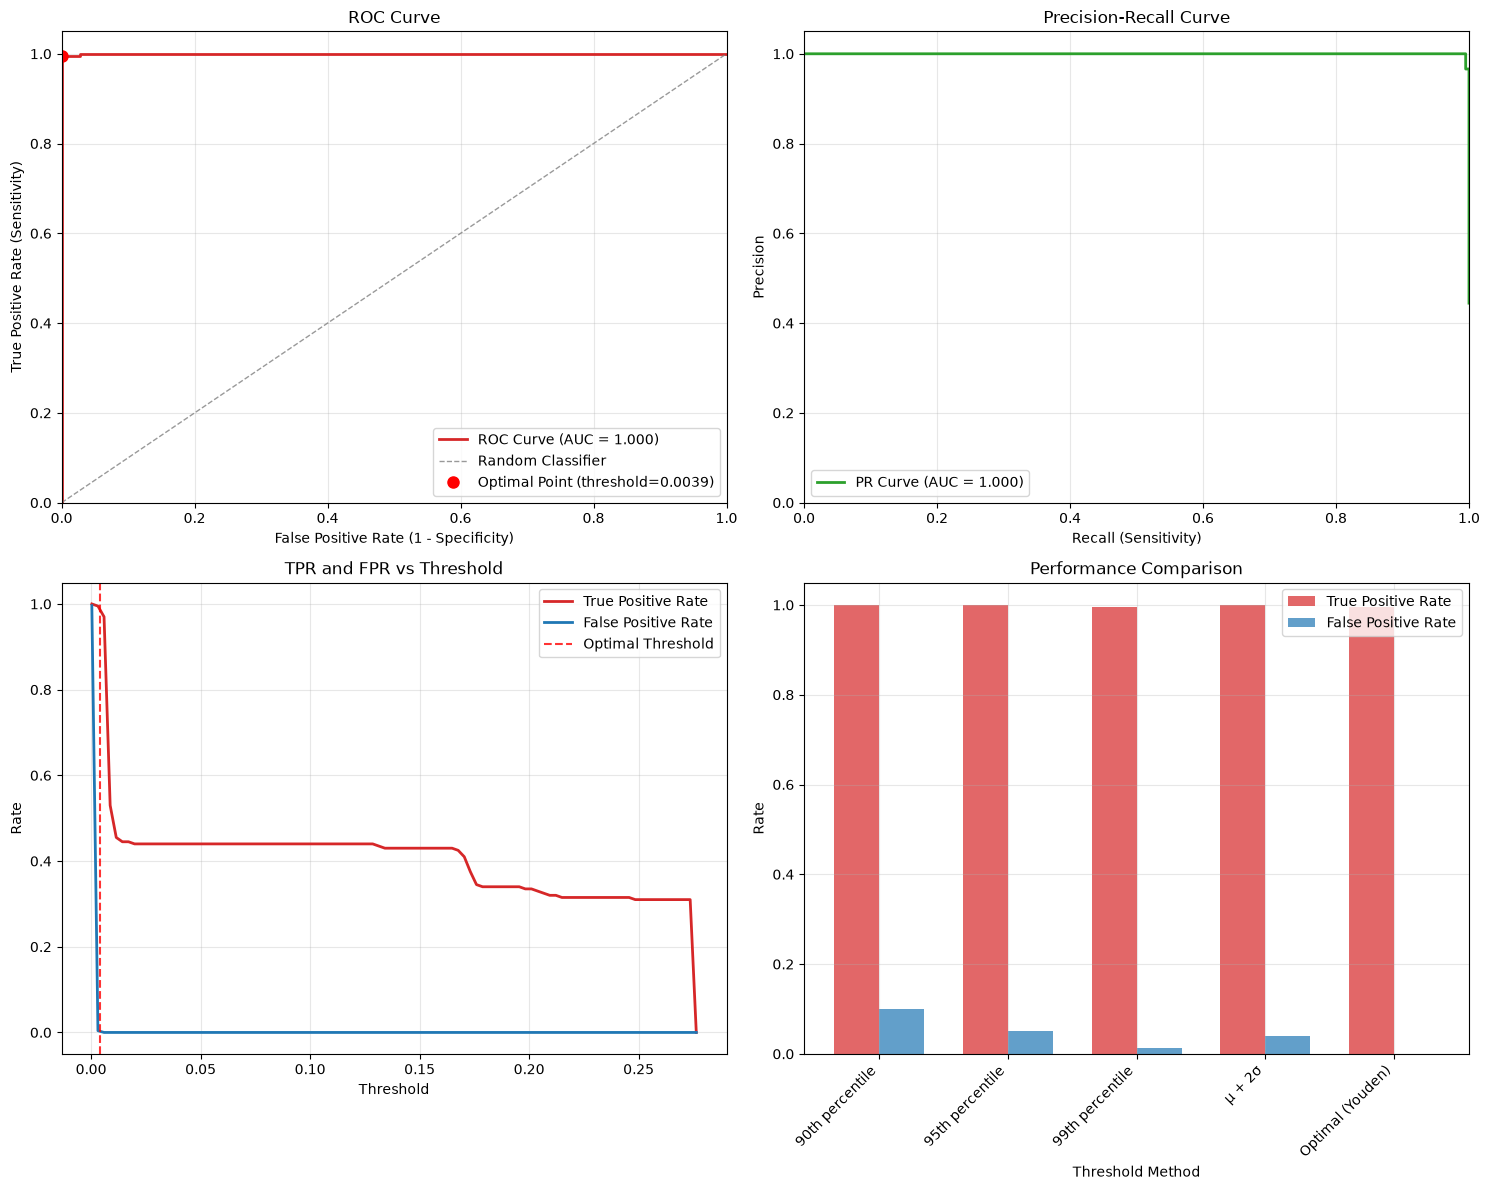


📊 ROC Analysis Results:
   • ROC AUC: 1.000
   • PR AUC: 1.000
   • Optimal threshold (Youden's): 0.003937
   • At optimal threshold - TPR: 0.995, FPR: 0.000

📋 Threshold Method Comparison:
Method          Threshold    TPR      FPR      Precision
-------------------------------------------------------
90th percentile 0.001660     1.000    0.100    0.889   
95th percentile 0.001802     1.000    0.052    0.939   
99th percentile 0.002744     0.995    0.012    0.985   
μ + 2σ          0.001976     1.000    0.040    0.952   
Optimal (Youden) 0.003937     0.995    0.000    0.952   

🎯 Performance Interpretation:
   • Excellent discrimination (AUC ≥ 0.9)

✅ ROC analysis complete!


In [12]:
# ROC Curve Analysis
if (
    evaluation_complete
    and "normal_errors_best" in locals()
    and "anomaly_errors_best" in locals()
):
    print(f"\n📈 ROC Curve Analysis for {best_fold_name}")
    roc_results = visualizer.plot_roc_analysis(
        normal_errors_best, anomaly_errors_best, test_anomaly_classes_best
    )

    print("\n✅ ROC analysis complete!")
else:
    print("❌ ROC analysis requires valid reconstruction errors from previous cell")

> ⚠️ **Read the AUC with care.** With the toolkit `Normalize` as the default scaler, the statistics come from the training events and the **absolute level of each sensor is kept**, so an anomaly differs from normal operation in level and not only in shape. That is why the autoencoder separates the classes almost perfectly here (AUC close to 1.0). With the per-event Min-Max of the earlier version, which erases the levels, the same notebook gives an autoencoder AUC of 0.96 and the one-class SVM an AUC of 0.97. The gap measures how much of the detection comes from the level of the sensors, not from the temporal pattern. Part of that level is also a fingerprint of the well: notebook 4 shows that, with the toolkit `Normalize`, a window identifies its well about 96 % of the time (section *Does the sensor level identify the well?*). To reproduce the comparison, set `DEFAULT_SCALING_METHOD = "minmax"` in `src/config.py` and re-run notebooks 1 and 3.

## 📖 Guided exercises (book, Appendix E — exercises 2, 4 and 7)

1. Change `SAMPLING_RATE` from 5 to 1 in `src/config.py`, re-run notebook 1 and then this notebook. Does the reconstruction error improve or get worse? Separate the effect of the higher resolution from the effect of the change in the time covered by the window.
2. Compare the **95th-percentile** threshold with **μ + 2σ** on the same reconstruction errors. Build the ROC curve and locate both thresholds on it.
3. Extend this notebook to extract the penultimate layer of one of the classifiers of notebook 4 and compute the **Mahalanobis distance** in that space. Can you reproduce, at small scale, the jump described in Chapter 12 of the book?

> 📖 *Lopes et al. (2026), Appendix E — "Roteiro prático com o repositório 3W"* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)).